# Projeto de Detecção de Fraude em Transações - Ciência de Dados

**Propósito:**  
Verificar vários modelos de classificação supervisionada com base em dados já categorizados. A variável "Class" indica se a transação é fraude (1) ou não fraude (0).

**Fluxo:**
* Importação de dados do credcard;
* Analisa a proporção da variável "class" identificando se base está ou não balanceada;
* Feature engineering;
* Segrega dados - treino  e teste;
* Modelo 1 - Regressão logística
    * ROC Curve;
    * Precision Recall Curve.
* Modelo 2 - Árvores Combinatórias
    * ROC Curve;
    * Precision Recall Curve.
* Modelo 3 - XGBoost
    * ROC Curve;
    * Precision Recall Curve.

In [ ]:
#1 Importação da informações de cartão de crédito

import pandas as pd

url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

dado= pd.read_csv(url)

dado.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


##2. Valida class ⚛
Verifica o percentual de fraude (1) e não fraude (0).

**Observação:** esta validação da proporção da variável "class" identifica que a base está *desbalanceada*.

In [ ]:
#2 - Validar Class (Se 1 fraude e se 0 não fraude)

dado["Class"].value_counts(normalize = True)

,proportion
Class,
0,0.998273
1,0.001727


##Feature engineering

##Scaler - média = 0 e desvio padrão = 1

Valores ficam na mesma escala independente dos valores originais - valores muito grandes e pequenos podem ser comparados.

**Observação:**
* Valores ficam na mesma escala independente dos valores originais, logo, valores muito grandes e pequenos podem ser comparados.



In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
dado["Amount_scaled"] = scaler.fit_transform(dado[["Amount"]])
dado.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Amount_scaled
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0,0.244964
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0,-0.342475
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0,1.160686
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0,0.140534
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0,-0.073403


##Segrega os dados em treino e teste. (treino analia, testa depois avaliação)

Observação -> serão 30 % de dados testados e 70% de dados de treino. (test_size)

stratify = y -> mantém que a proporção de "fraude" e "não fraude" seja mantida.tanto no treino quanto no teste. Afinal os dados estão desbalanceados e pode comprometer a avaliação.

random_state -> 42 para manter reprodutibilidade - reproduzior os mesmos resultados em diferentes análises , mesmo que em momentos e usuários diferentes desde que as condições iniciais sejam mantidas.

In [ ]:
from sklearn.model_selection import train_test_split

X = dado.drop(["Class"], axis = 1)
y = dado["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify = y, test_size=0.3, random_state=42
    )

##Regressão logística

Primeiro modelo - vê se os outros estão funcionando.

Observações:

*   max_inter -> números de interações que o algoritmo convergirá;


In [ ]:
from sklearn.linear_model import LogisticRegression


model = LogisticRegression(max_iter=1000)

# Treinando o modelo com os dados corrigidos
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


##Classification report

Imprime as métricas mais importantes da avaliação.

**Observação sobre as métricas:**

* Precision -> A precisão mede a proporção de verdadeiros positivos em relação ao total de positivos previstos (verdadeiros positivos + falsos positivos). (VP / (VP + FP)).
* Recall ->O recall mede a proporção de verdadeiros positivos em relação ao total de positivos reais (verdadeiros positivos + falsos negativos). (VP / (VP + FN)).
* F1-Score -> é a média harmônica entre precisão e recall, fornecendo um único valor que representa a performance do modelo em relação a estas duas métricas.
* Accuracy -> A acurácia  indica se o modelo classificou corretamente todas as instâncias do conjunto de teste.


**Observações sobre o resultado:**
*   Desempenho Global: Embora a acurácia seja 100%, o recall relativamente baixo de 0,68 indica que o modelo pode não estar identificando todos os casos positivos de forma eficaz. Isso é um sinal de que, mesmo com a acurácia perfeita, o modelo pode ter problemas em identificar corretamente a classe positiva.
*   Problema de Desbalanceamento: É importante considerar que você tem um problema de desbalanceamento nas classes. Logo, a classe negativa é muito mais prevalente do que a positiva, um modelo pode alcançar alta acurácia simplesmente prevendo a classe negativa na maioria das vezes.
*    Foco em Aplicações: Dependendo do contexto em que esse modelo será usado, pode ser necessário ajustar mais para aumentar o recall, especialmente se identificar os casos positivos é crítico.
Em resumo, embora a acurácia seja alta, as métricas de precisão e recall sugerem que o modelo ainda pode ser melhorado, especialmente em termos de sua capacidade de detectar casos positivos.

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.84      0.66      0.73       148

    accuracy                           1.00     85443
   macro avg       0.92      0.83      0.87     85443
weighted avg       1.00      1.00      1.00     85443



##Curva Roc
Demonstra o desempenho do modelo em diferentes limiares de decisão.

*  Eixo horizontal: taxa de falso positivo (modelo classifica instância negativa de positiva)
*  Eixo vertical: taxa de verdadeiro positivo (modelo acerta a classificação da instância)


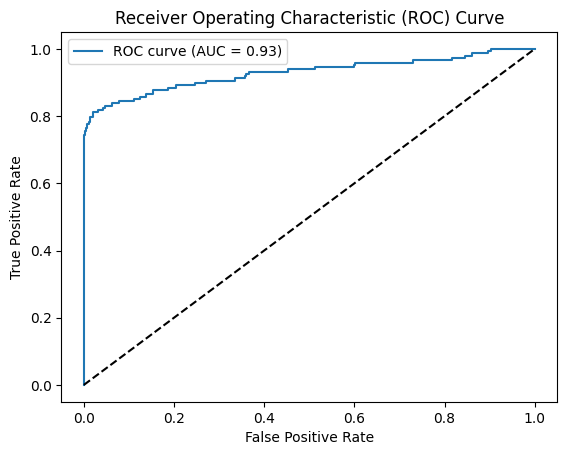

AUC: 0.9283458204672814


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_probs = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = roc_auc_score(y_test, y_probs)
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.show()
print("AUC:", roc_auc)



## Precision-Recall Curve
Métrica importante em modelos de dados desbalanceados. Esta mostra o equilíbrio (trade off) entre as duas variáveis (recall e precision).


*   Eixo horizontal -> recall;
*   Eixo vertical -> precision.

**Observações sobre o resultado do gráfico:**
- Início curva -> início próximo de 1 aponta fraude com muita certeza entretanto o recall baixo muitas fraudes passam despercebidas;
- Meio curva -> recall aumenta identificando fraude entretanto o precision cai e aumenta o falso positivo;
- Final curva -> recall alto e precision baixo modelo com muitas transações setadas como fraude entretanto várias não são.

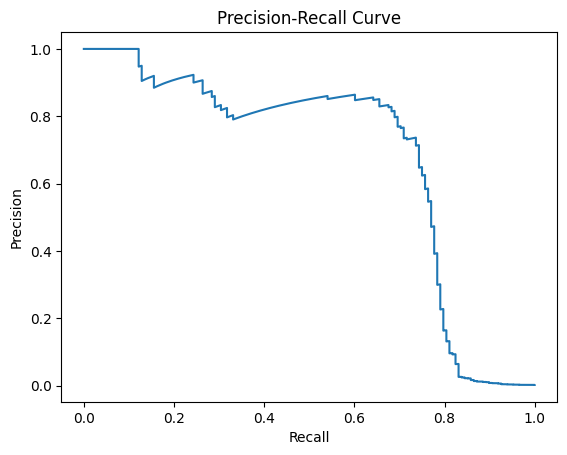

In [ ]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, y_probs)
plt.plot(recall, precision)
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

##Modelo Floresta Aleatória- Random Forest Classifier
Modelo de classificação mais avançado que a regressão logística. Conjunto de várias árvores de decisão.

**Parametros utilizados:**
* n_estimators=50: Este parâmetro define o número de árvores que serão construídas na floresta. Um número maior de estimadores geralmente leva a um modelo mais robusto, mas também aumenta o tempo de processamento. 50 árvores.
* max_depth=10: Este parâmetro especifica a profundidade máxima de cada árvore individual na floresta. Limitar a profundidade das árvores ajuda a evitar o overfitting, que ocorre quando o modelo se ajusta demais aos dados de treinamento, perdendo a capacidade de generalizar para novos dados.
* class_weight="balanced": Este parâmetro ajusta os pesos das classes para lidar com desbalanceamentos nos dados. Quando você define class_weight como "balanced", o modelo ajusta automaticamente os pesos das classes inversamente proporcionais à frequência de cada classe no conjunto de dados. Isso é útil para evitar que uma classe dominante influencie excessivamente o modelo.
* n_jobs=-1: Este parâmetro especifica quantos trabalhos (ou núcleos) usar para treinar o modelo. Definir n_jobs como -1 instrui o modelo a usar todos os núcleos disponíveis da CPU, o que pode acelerar o processo de treinamento.
* random_state=42: Este parâmetro é usado para garantir que os resultados sejam reprodutíveis. Definindo uma semente aleatória (neste caso, 42), você pode garantir que o processo aleatório do modelo (como a seleção de subconjuntos de dados ou a inicialização de árvores) seja consistente entre diferentes execuções do código.

**Resultados:**
Esses resultados sugerem que o modelo funciona excepcionalmente bem na previsão da classe majoritária, mas suas previsões para a classe minoritária (1) não são tão robustas. Em problemas de classificação com classes desbalanceadas, é importante não apenas olhar a acurácia, mas também considerar métricas que dêem uma melhor visão do desempenho em todas as classes, como precisão, recall e F1-score.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rt = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)
rt.fit(X_train, y_train)
y_pred = rt.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.83      0.76      0.80       148

    accuracy                           1.00     85443
   macro avg       0.92      0.88      0.90     85443
weighted avg       1.00      1.00      1.00     85443



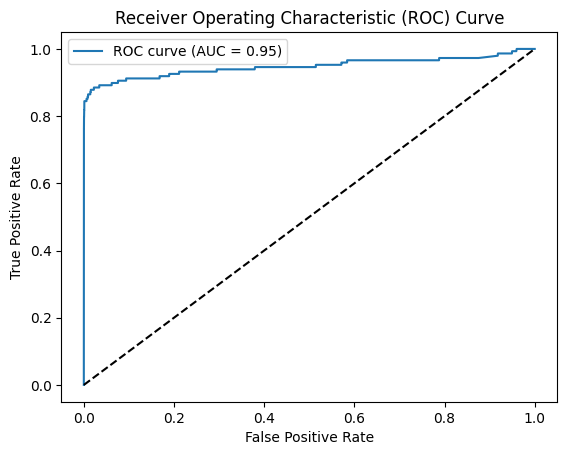

AUC: 0.9474310144601487


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_probs = rt.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = roc_auc_score(y_test, y_probs)
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.show()
print("AUC:", roc_auc)


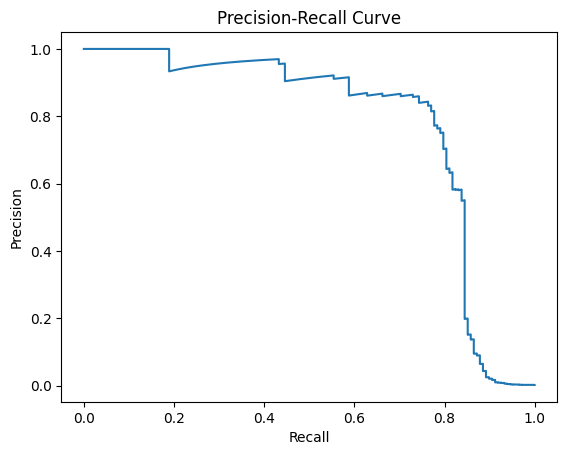

In [ ]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, y_probs)
plt.plot(recall, precision)
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

##Modelo avançado GXBoost
Modelo baseado em boosting - técnica onde vários modelos são treinados em sequẽncia e cada novo modelo tenta corrigir o anterior.

**Parametros: utilizados:**

 - use_label_encoder=False -> Este parâmetro é utilizado para desabilitar o uso do LabelEncoder interno do XGBoost, que era necessário em versões anteriores para tratar rótulos de classes. A partir da versão 1.3.0 do XGBoost, o uso do LabelEncoder é desaconselhado, pois pode gerar avisos, e defini-lo como False evita esse comportamento indesejado.

 - scale_pos_weight=10 -> Este parâmetro é usado para lidar com classes desbalanceadas no conjunto de dados. O parâmetro scale_pos_weight ajusta a proporção de amostras positivas em relação às amostras negativas. Se a classe positiva estiver muito menos frequente que a negativa (como é este caso), aumentar o scale_pos_weight pode ajudar o modelo a prestar mais atenção a essas instâncias menos frequentes, melhorando a sua capacidade de prever a classe positiva.

 - eval_metric="logloss" -> O parâmetro eval_metric define a métrica que será utilizada para avaliar a performance do modelo durante o treinamento e a validação. Neste caso, o log loss (também conhecido como logaritmo da perda de verossimilhança) é usado como medida de desempenho. O log loss é especialmente relevante em problemas de classificação, pois penaliza predições incorretas com base na confiança que o modelo tinha em suas previsões (quanto mais confiante, maior a penalização se a previsão estiver errada).

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

xgb = XGBClassifier(
    use_label_encoder=False,
    scale_pos_weight=10,
    eval_metric="logloss"
)

xgb.fit(X_train, y_train)
y_pred = xgb.predict(X_test)
print(classification_report(y_test, y_pred))
#

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [02:02:04] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.94      0.78      0.85       148

    accuracy                           1.00     85443
   macro avg       0.97      0.89      0.93     85443
weighted avg       1.00      1.00      1.00     85443



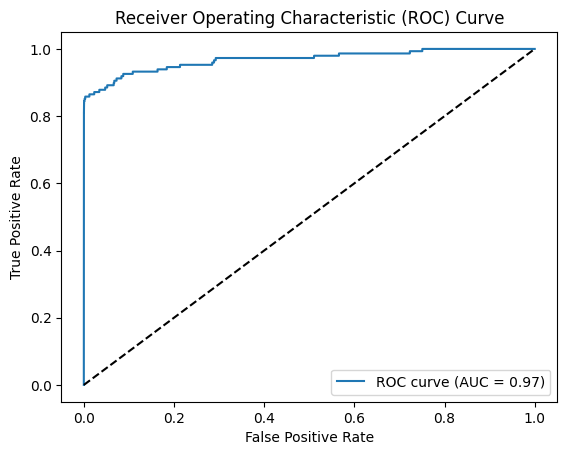

AUC: 0.9686524747973251


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_probs = xgb.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = roc_auc_score(y_test, y_probs)
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.show()
print("AUC:", roc_auc)

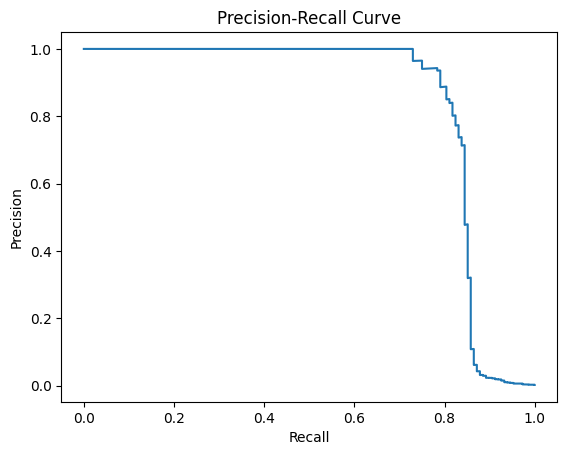

In [ ]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, y_probs)
plt.plot(recall, precision)
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

##Resultado

Na atividade de classificação de fraudes, foram gerados três modelos, e o melhor desempenho GXBoost.

**Resultados avaliação:**

* Sobre o relatório de classificação -> A classe 1, que representa as transações fraudulentas, o modelo apresentou uma precisão de 0.94. Isso significa que 94% das transações identificadas como fraudulentas pelo modelo eram, de fato, fraudes. No entanto, o recall para essa classe foi de 0.78, indicando que apenas 78% das transações fraudulentas reais foram corretamente identificadas pelo modelo. Como resultado, o F1-score para a classe de fraudes ficou em 0.85, evidenciando a média harmônica entre as variáveis anteriores.

* Sobre a curva ROC (Receiver Operating Characteristic) para o modelo alcançou um valor de 0.96, o que indica uma excelente capacidade de distinção entre as classes, evidenciando que o modelo foi eficaz em identificar tanto transações legítimas quanto fraudulentas.
*Observação:*Uma área sob a curva (AUC) próxima de 1.0 é geralmente considerada um indicativo de um bom desempenho de classificação.

Em suma, o modelo demonstrou-se bastante eficaz na identificação de transações legítimas, e um melhor desempenho em detectar fraudes reais.